In [2]:
import mysql.connector
import pandas as pd

In [5]:
# Connect to MYSQL 
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Rajesh@6360",
    database="Deloitte_Fraud_Detection_Analytics"
)
print("connected successfully")

connected successfully


In [6]:
query = "SELECT * FROM fraud_transactions"
df = pd.read_sql(query, connection)

df


C:\Users\rajes\AppData\Local\Temp\ipykernel_13876\2841890340.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


,Transaction_ID,Customer_ID,Transaction_Date,Amount,Country,City,Channel,Payment_Method,Merchant_Category,Device_Type,...,Avg_Transaction_Amount,Distance_From_Home_KM,Failed_Attempts_24H,IP_Risk_Score,Device_Risk_Score,Fraud_Flag,Fraud_Type,Risk_Level,Fraud_Score,Review_Status
0,TXN110286,CUST14957,2025-01-01 00:05:00,1394.61,India,Hyderabad,POS,Credit Card,Entertainment,Desktop,...,2392.58,1.12,0,38.97,16.35,0,None,Medium,0.68,Cleared
1,TXN109365,CUST13420,2025-01-01 00:15:00,2563.83,India,Mumbai,Online,Wallet,Healthcare,Desktop,...,3834.03,7.38,0,1.84,36.69,0,None,Medium,0.52,Cleared
2,TXN107226,CUST10537,2025-01-01 00:37:00,2725.02,India,Hyderabad,Mobile App,UPI,Grocery,Mobile,...,1716.01,0.47,0,28.96,45.02,0,None,Medium,6.87,Cleared
3,TXN117812,CUST12104,2025-01-01 00:56:00,1645.59,India,Kolkata,Mobile App,Wallet,Electronics,Mobile,...,2934.90,4.98,0,23.74,11.21,0,None,Medium,0.00,Cleared
4,TXN110105,CUST10591,2025-01-01 01:04:00,914.87,India,Ahmedabad,POS,Debit Card,Travel,Desktop,...,1785.78,15.75,1,14.35,14.93,0,None,Medium,6.61,Cleared
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,TXN112190,CUST12704,2025-12-31 20:58:00,1546.14,UAE,Ahmedabad,POS,Net Banking,Grocery,Tablet,...,1730.24,10.16,0,25.86,16.67,0,None,Medium,12.74,Cleared
19996,TXN115582,CUST12043,2025-12-31 22:16:00,3317.78,UAE,Bengaluru,POS,Net Banking,Grocery,Mobile,...,4876.18,45.53,0,15.96,18.88,0,None,Medium,0.00,Cleared
19997,TXN112425,CUST10390,2025-12-31 23:47:00,4796.94,India,Bengaluru,ATM,UPI,Travel,Mobile,...,2375.07,54.54,0,43.33,53.29,1,Card Fraud,High,8.37,Under Review
19998,TXN110754,CUST14178,2025-12-31 23:49:00,2688.70,USA,Kolkata,Online,Credit Card,Travel,Mobile,...,1788.54,16.41,0,18.74,58.46,0,None,Medium,2.66,Cleared


In [7]:
import matplotlib.pyplot as plt

In [8]:
import seaborn as sns 

In [9]:
import numpy as np

In [10]:
import sklearn

In [11]:
df.head()

,Transaction_ID,Customer_ID,Transaction_Date,Amount,Country,City,Channel,Payment_Method,Merchant_Category,Device_Type,...,Avg_Transaction_Amount,Distance_From_Home_KM,Failed_Attempts_24H,IP_Risk_Score,Device_Risk_Score,Fraud_Flag,Fraud_Type,Risk_Level,Fraud_Score,Review_Status
0,TXN110286,CUST14957,2025-01-01 00:05:00,1394.61,India,Hyderabad,POS,Credit Card,Entertainment,Desktop,...,2392.58,1.12,0,38.97,16.35,0,None,Medium,0.68,Cleared
1,TXN109365,CUST13420,2025-01-01 00:15:00,2563.83,India,Mumbai,Online,Wallet,Healthcare,Desktop,...,3834.03,7.38,0,1.84,36.69,0,None,Medium,0.52,Cleared
2,TXN107226,CUST10537,2025-01-01 00:37:00,2725.02,India,Hyderabad,Mobile App,UPI,Grocery,Mobile,...,1716.01,0.47,0,28.96,45.02,0,None,Medium,6.87,Cleared
3,TXN117812,CUST12104,2025-01-01 00:56:00,1645.59,India,Kolkata,Mobile App,Wallet,Electronics,Mobile,...,2934.90,4.98,0,23.74,11.21,0,None,Medium,0.00,Cleared
4,TXN110105,CUST10591,2025-01-01 01:04:00,914.87,India,Ahmedabad,POS,Debit Card,Travel,Desktop,...,1785.78,15.75,1,14.35,14.93,0,None,Medium,6.61,Cleared


In [13]:
df.shape

(20000, 23)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Transaction_ID          20000 non-null  object 
 1   Customer_ID             20000 non-null  object 
 2   Transaction_Date        20000 non-null  object 
 3   Amount                  20000 non-null  float64
 4   Country                 20000 non-null  object 
 5   City                    20000 non-null  object 
 6   Channel                 20000 non-null  object 
 7   Payment_Method          20000 non-null  object 
 8   Merchant_Category       20000 non-null  object 
 9   Device_Type             20000 non-null  object 
 10  Customer_Age            20000 non-null  int64  
 11  Account_Age_Days        20000 non-null  int64  
 12  Transaction_Count_24H   20000 non-null  int64  
 13  Avg_Transaction_Amount  20000 non-null  float64
 14  Distance_From_Home_KM   20000 non-null

Missing values

In [15]:
df.isnull().sum()

Transaction_ID            0
Customer_ID               0
Transaction_Date          0
Amount                    0
Country                   0
City                      0
Channel                   0
Payment_Method            0
Merchant_Category         0
Device_Type               0
Customer_Age              0
Account_Age_Days          0
Transaction_Count_24H     0
Avg_Transaction_Amount    0
Distance_From_Home_KM     0
Failed_Attempts_24H       0
IP_Risk_Score             0
Device_Risk_Score         0
Fraud_Flag                0
Fraud_Type                0
Risk_Level                0
Fraud_Score               0
Review_Status             0
dtype: int64

Duplicate transactions

In [16]:
df["Transaction_ID"].duplicated().sum()

np.int64(0)

EDA

In [17]:
df["Fraud_Flag"].value_counts()

Fraud_Flag
0    19007
1      993
Name: count, dtype: int64

Fraud percentage

In [18]:
df["Fraud_Flag"].value_counts(normalize=True) * 100

Fraud_Flag
0    95.035
1     4.965
Name: proportion, dtype: float64

Fraud by payment method

In [19]:
df.groupby("Payment_Method")["Fraud_Flag"].mean().sort_values(ascending=False)

Payment_Method
Net Banking    0.054852
Debit Card     0.051102
Wallet         0.049776
Credit Card    0.048040
UPI            0.044433
Name: Fraud_Flag, dtype: float64

Fraud by channel

In [20]:
df.groupby("Channel")["Fraud_Flag"].mean().sort_values(ascending=False)

Channel
Mobile App    0.054703
ATM           0.050671
Online        0.048668
POS           0.042774
Name: Fraud_Flag, dtype: float64

Fraud amount

In [21]:
df[df["Fraud_Flag"] == 1]["Amount"].sum()

np.float64(2154372.84)

Average fraud transaction

In [22]:
df[df["Fraud_Flag"] == 1]["Amount"].mean()

np.float64(2169.559758308157)

Fraud vs Non-Fraud Transactions

In [23]:
df["Fraud_Flag"].value_counts()

fraud_counts = df["Fraud_Flag"].value_counts()

labels = ["Non-Fraud", "Fraud"]
values = [
    fraud_counts.get(0, 0),
    fraud_counts.get(1, 0)
]

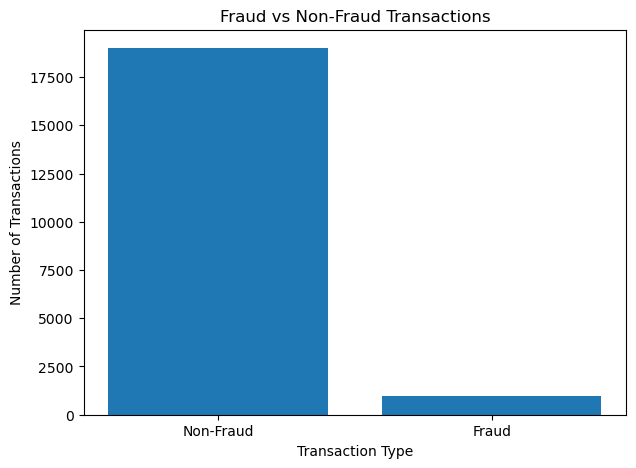

In [24]:
plt.figure(figsize=(7,5))

plt.bar(labels, values)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

Fraud Rate by Payment Method

In [26]:
fraud_payment = (
    df.groupby("Payment_Method")["Fraud_Flag"]
    .mean()
    .sort_values(ascending=False)
)

fraud_payment_percentage = fraud_payment * 100

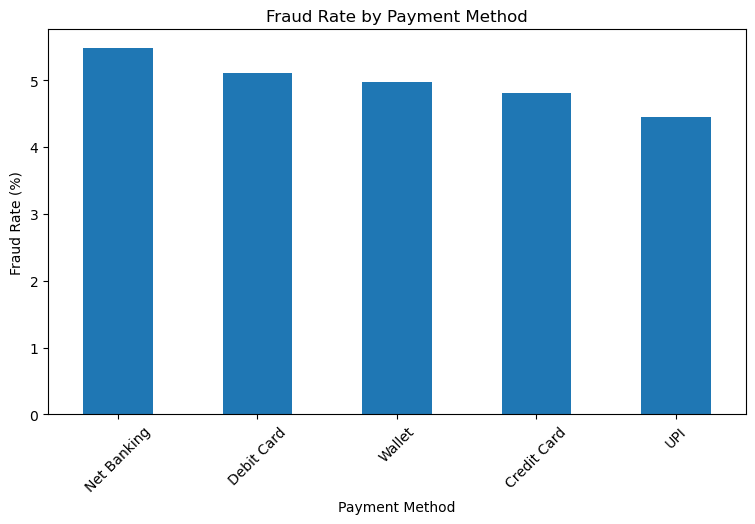

In [27]:
plt.figure(figsize=(9,5))

fraud_payment_percentage.plot(kind="bar")

plt.title("Fraud Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=45)
plt.show()

Fraud Rate by Channel

In [28]:
fraud_channel = (
    df.groupby("Channel")["Fraud_Flag"]
    .mean()
    .sort_values(ascending=False)
)
fraud_channel_percentage = fraud_channel * 100

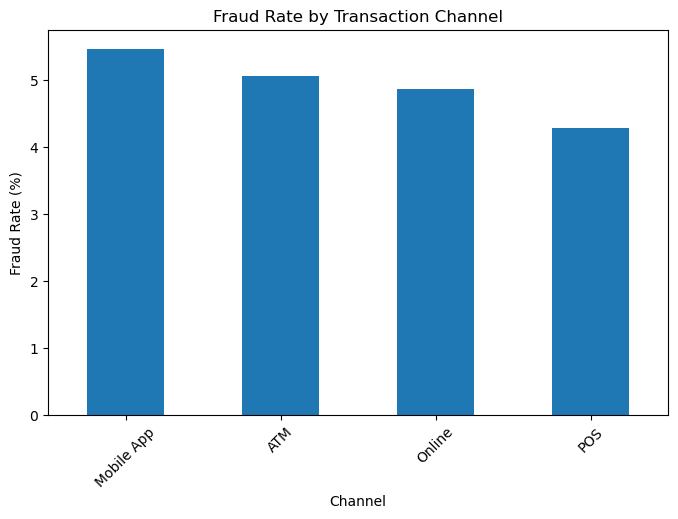

In [29]:
plt.figure(figsize=(8,5))

fraud_channel_percentage.plot(kind="bar")

plt.title("Fraud Rate by Transaction Channel")
plt.xlabel("Channel")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=45)
plt.show()

Fraud by Merchant Category

In [30]:
fraud_merchant = (
    df[df["Fraud_Flag"] == 1]
    .groupby("Merchant_Category")
    .size()
    .sort_values(ascending=False)
)

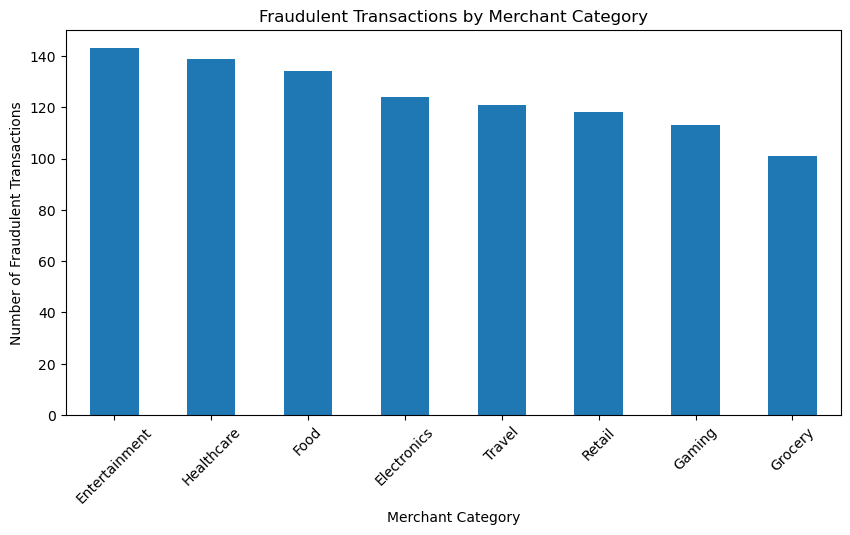

In [31]:
plt.figure(figsize=(10,5))

fraud_merchant.plot(kind="bar")

plt.title("Fraudulent Transactions by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Number of Fraudulent Transactions")

plt.xticks(rotation=45)
plt.show()

Fraud by Country

In [32]:
fraud_country = (
    df[df["Fraud_Flag"] == 1]
    .groupby("Country")
    .size()
    .sort_values(ascending=False)
)

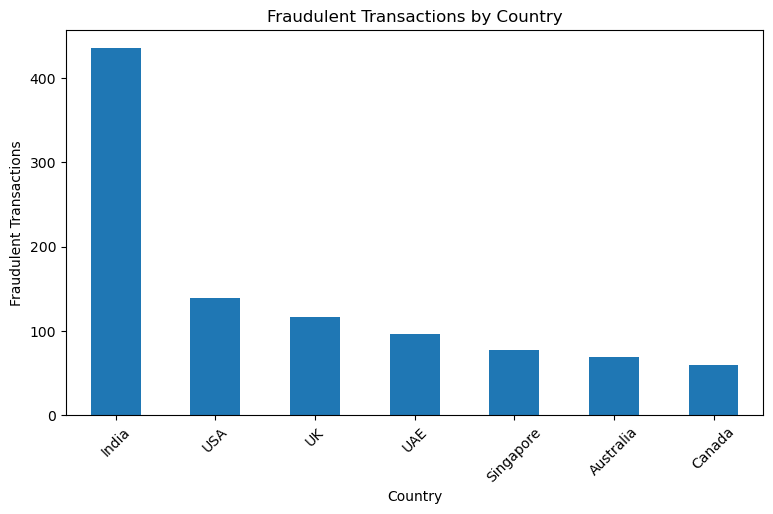

In [33]:
plt.figure(figsize=(9,5))

fraud_country.plot(kind="bar")

plt.title("Fraudulent Transactions by Country")
plt.xlabel("Country")
plt.ylabel("Fraudulent Transactions")

plt.xticks(rotation=45)
plt.show()

Fraud Amount by Month

In [35]:
df["Transaction_Date"] = pd.to_datetime(
    df["Transaction_Date"]
)
df["Month"] = df["Transaction_Date"].dt.to_period("M")

fraud_monthly = (
    df[df["Fraud_Flag"] == 1]
    .groupby("Month")["Amount"]
    .sum()
)

fraud_monthly.index = fraud_monthly.index.astype(str)

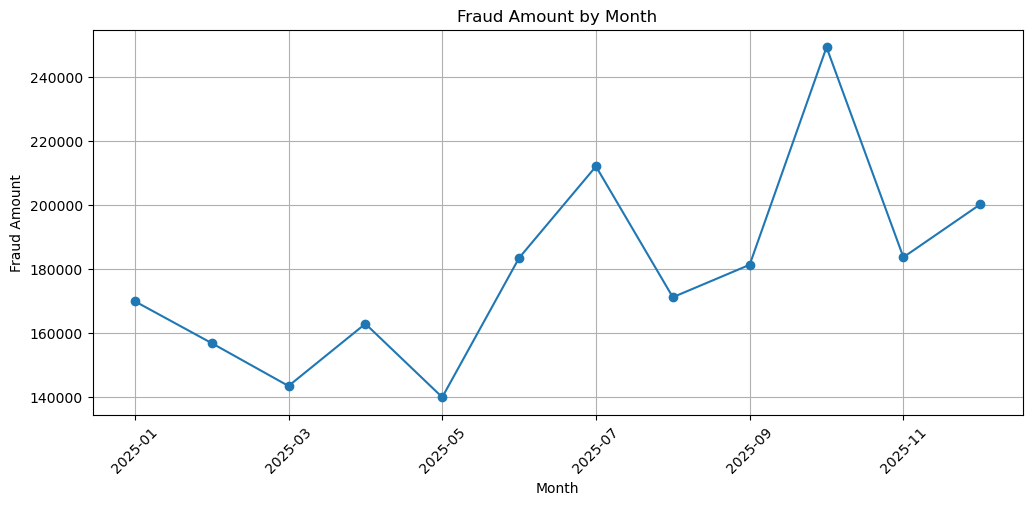

In [36]:
plt.figure(figsize=(12,5))

fraud_monthly.plot(kind="line", marker="o")

plt.title("Fraud Amount by Month")
plt.xlabel("Month")
plt.ylabel("Fraud Amount")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

Fraud Type Distribution

In [37]:
fraud_type = (
    df[df["Fraud_Flag"] == 1]
    ["Fraud_Type"]
    .value_counts()
)


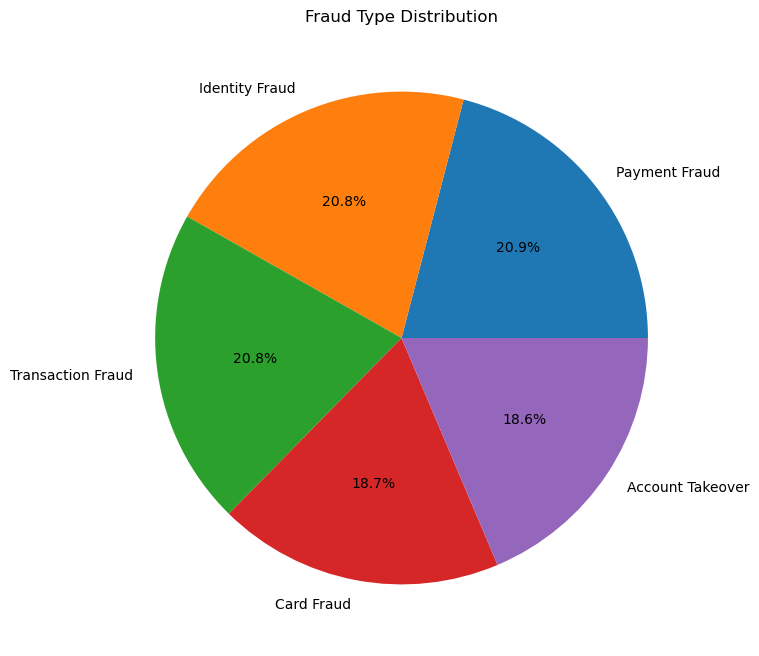

In [38]:
plt.figure(figsize=(8,8))

plt.pie(
    fraud_type.values,
    labels=fraud_type.index,
    autopct="%1.1f%%"
)

plt.title("Fraud Type Distribution")

plt.show()

IP Risk Score vs Fraud

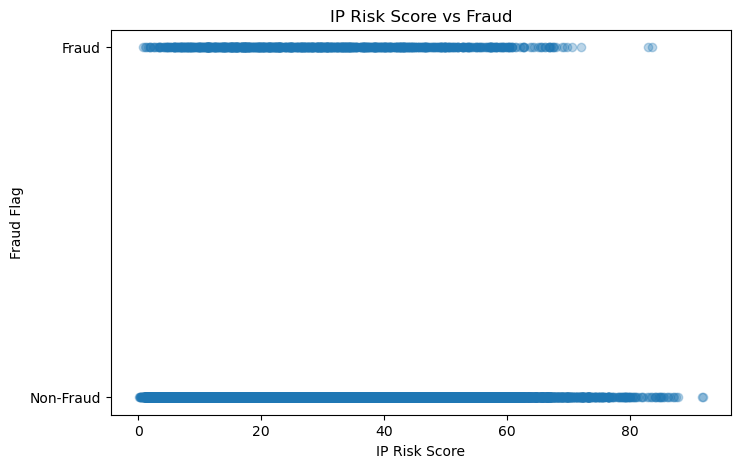

In [42]:

plt.figure(figsize=(8,5))

plt.scatter(
    df["IP_Risk_Score"],
    df["Fraud_Flag"],
    alpha=0.3
)

plt.title("IP Risk Score vs Fraud")
plt.xlabel("IP Risk Score")
plt.ylabel("Fraud Flag")

plt.yticks([0,1], ["Non-Fraud", "Fraud"])

plt.show()

In [43]:
df["IP_Risk_Band"] = pd.cut(
    df["IP_Risk_Score"],
    bins=[0,20,40,60,80,100],
    labels=["0-20","21-40","41-60","61-80","81-100"],
    include_lowest=True
)

ip_risk_fraud = (
    df.groupby("IP_Risk_Band", observed=False)["Fraud_Flag"]
    .mean() * 100
)

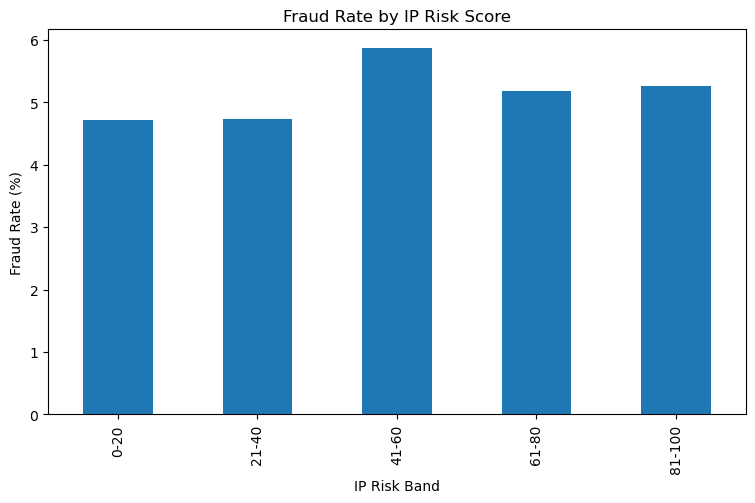

In [44]:
plt.figure(figsize=(9,5))

ip_risk_fraud.plot(kind="bar")

plt.title("Fraud Rate by IP Risk Score")
plt.xlabel("IP Risk Band")
plt.ylabel("Fraud Rate (%)")

plt.show()

Device Risk Score vs Fraud


In [45]:
df["Device_Risk_Band"] = pd.cut(
    df["Device_Risk_Score"],
    bins=[0,20,40,60,80,100],
    labels=["0-20","21-40","41-60","61-80","81-100"],
    include_lowest=True
)
device_risk_fraud = (
    df.groupby("Device_Risk_Band", observed=False)["Fraud_Flag"]
    .mean() * 100
)

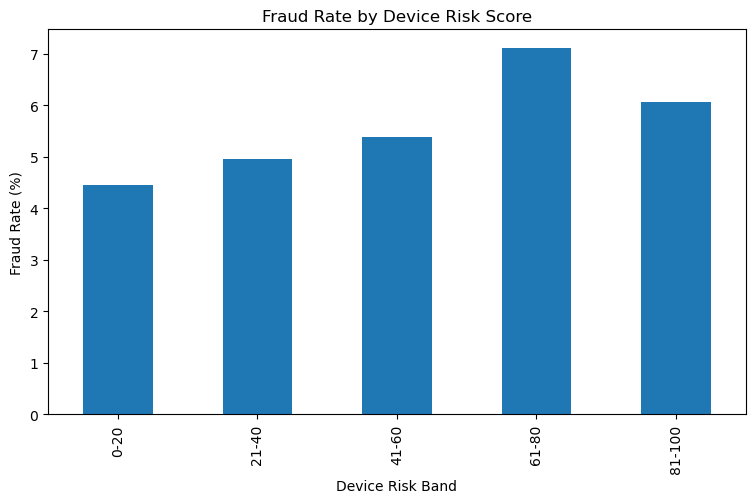

In [46]:
plt.figure(figsize=(9,5))

device_risk_fraud.plot(kind="bar")

plt.title("Fraud Rate by Device Risk Score")
plt.xlabel("Device Risk Band")
plt.ylabel("Fraud Rate (%)")

plt.show()

Transaction Amount Distribution

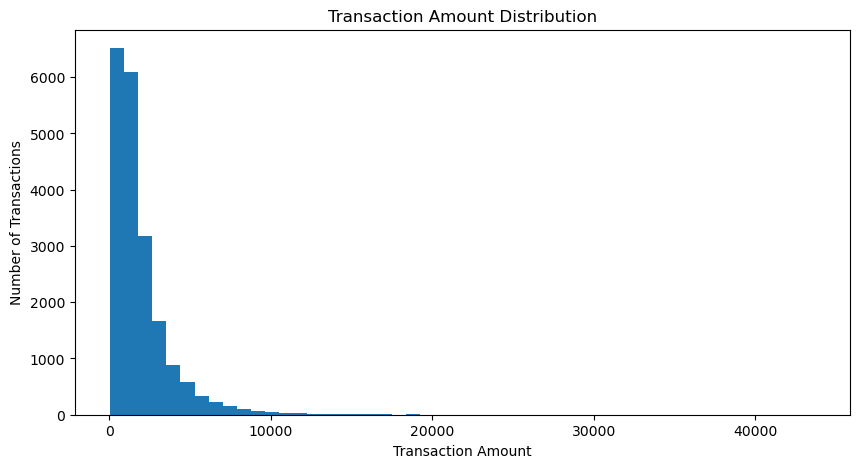

In [47]:
plt.figure(figsize=(10,5))

plt.hist(
    df["Amount"],
    bins=50
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

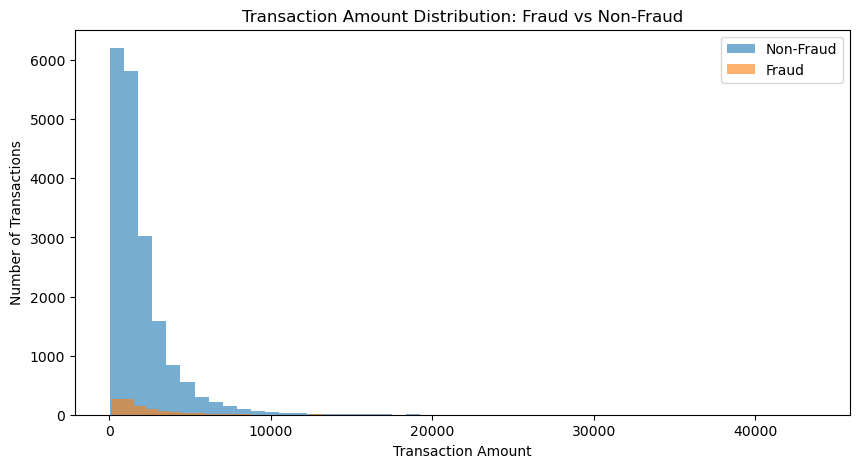

In [48]:
plt.figure(figsize=(10,5))

plt.hist(
    df[df["Fraud_Flag"] == 0]["Amount"],
    bins=50,
    alpha=0.6,
    label="Non-Fraud"
)

plt.hist(
    df[df["Fraud_Flag"] == 1]["Amount"],
    bins=50,
    alpha=0.6,
    label="Fraud"
)

plt.title("Transaction Amount Distribution: Fraud vs Non-Fraud")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.legend()

plt.show()

Fraud Risk Analysis

Transaction Amount

In [49]:
non_fraud_avg = df[
    df["Fraud_Flag"] == 0
]["Amount"].mean()

non_fraud_avg

fraud_avg = df[
    df["Fraud_Flag"] == 1
]["Amount"].mean()

fraud_avg

np.float64(2169.559758308157)

In [50]:
print("Average Non-Fraud Amount:", non_fraud_avg)
print("Average Fraud Amount:", fraud_avg)

Average Non-Fraud Amount: 1920.3200205187563
Average Fraud Amount: 2169.559758308157


IP Risk Score

In [51]:
df.groupby("Fraud_Flag")["IP_Risk_Score"].mean()

Fraud_Flag
0    28.503153
1    29.807251
Name: IP_Risk_Score, dtype: float64

Device Risk Score

In [52]:
df.groupby("Fraud_Flag")["Device_Risk_Score"].mean()

Fraud_Flag
0    28.592886
1    30.770614
Name: Device_Risk_Score, dtype: float64

Failed Attempts

In [53]:
df.groupby("Fraud_Flag")["Failed_Attempts_24H"].mean()

Fraud_Flag
0    0.491451
1    0.519637
Name: Failed_Attempts_24H, dtype: float64

In [55]:
df["Failed_Attempt_Band"] = pd.cut(
    df["Failed_Attempts_24H"],
    bins=[-1,0,1,2,5,100],
    labels=[
        "0",
        "1",
        "2",
        "3-5",
        "6+"
    ]
)

failed_attempt_analysis = (
    df.groupby(
        "Failed_Attempt_Band",
        observed=False
    )["Fraud_Flag"]
    .mean() * 100
)

failed_attempt_analysis

Failed_Attempt_Band
0      4.777096
1      5.287662
2      5.138607
3-5    5.319149
6+          NaN
Name: Fraud_Flag, dtype: float64

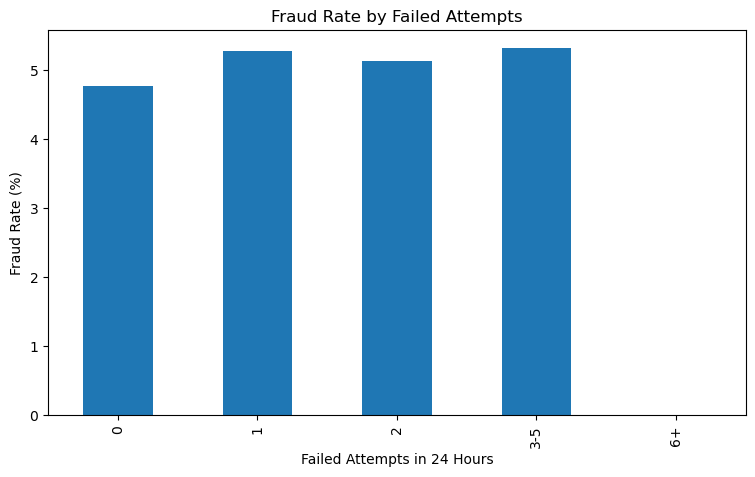

In [56]:
plt.figure(figsize=(9,5))

failed_attempt_analysis.plot(kind="bar")

plt.title("Fraud Rate by Failed Attempts")
plt.xlabel("Failed Attempts in 24 Hours")
plt.ylabel("Fraud Rate (%)")

plt.show()

Transaction Frequency

In [57]:
df.groupby("Fraud_Flag")[
    "Transaction_Count_24H"
].mean()


Fraud_Flag
0    5.007576
1    5.186304
Name: Transaction_Count_24H, dtype: float64

Distance From Home

In [58]:
df.groupby("Fraud_Flag")[
    "Distance_From_Home_KM"
].mean()

Fraud_Flag
0    14.888178
1    16.233061
Name: Distance_From_Home_KM, dtype: float64

In [61]:
df["Distance_Band"] = pd.cut(
    df["Distance_From_Home_KM"],
    bins=[0,5,20,50,100,10000],
    labels=[
        "0-5 KM",
        "6-20 KM",
        "21-50 KM",
        "51-100 KM",
        "100+ KM"
    ],
    include_lowest=True
)
distance_fraud = (
    df.groupby(
        "Distance_Band",
        observed=False
    )["Fraud_Flag"]
    .mean() * 100
)

Create a Risk-Factor Summary

In [62]:
risk_summary = pd.DataFrame({
    "Metric": [
        "Average Transaction Amount",
        "Average IP Risk Score",
        "Average Device Risk Score",
        "Average Failed Attempts",
        "Average Transactions in 24H",
        "Average Distance From Home"
    ],

    "Non-Fraud": [
        df[df["Fraud_Flag"] == 0]["Amount"].mean(),
        df[df["Fraud_Flag"] == 0]["IP_Risk_Score"].mean(),
        df[df["Fraud_Flag"] == 0]["Device_Risk_Score"].mean(),
        df[df["Fraud_Flag"] == 0]["Failed_Attempts_24H"].mean(),
        df[df["Fraud_Flag"] == 0]["Transaction_Count_24H"].mean(),
        df[df["Fraud_Flag"] == 0]["Distance_From_Home_KM"].mean()
    ],

    "Fraud": [
        df[df["Fraud_Flag"] == 1]["Amount"].mean(),
        df[df["Fraud_Flag"] == 1]["IP_Risk_Score"].mean(),
        df[df["Fraud_Flag"] == 1]["Device_Risk_Score"].mean(),
        df[df["Fraud_Flag"] == 1]["Failed_Attempts_24H"].mean(),
        df[df["Fraud_Flag"] == 1]["Transaction_Count_24H"].mean(),
        df[df["Fraud_Flag"] == 1]["Distance_From_Home_KM"].mean()
    ]
})

risk_summary

,Metric,Non-Fraud,Fraud
0,Average Transaction Amount,1920.320021,2169.559758
1,Average IP Risk Score,28.503153,29.807251
2,Average Device Risk Score,28.592886,30.770614
3,Average Failed Attempts,0.491451,0.519637
4,Average Transactions in 24H,5.007576,5.186304
5,Average Distance From Home,14.888178,16.233061


Create a Simple Risk Score

In [63]:
df["Calculated_Risk_Score"] = (
    df["IP_Risk_Score"] * 0.30 +
    df["Device_Risk_Score"] * 0.25 +
    (df["Failed_Attempts_24H"].clip(0,5) / 5 * 100) * 0.20 +
    (df["Transaction_Count_24H"].clip(0,15) / 15 * 100) * 0.15 +
    (df["Distance_From_Home_KM"].clip(0,100) / 100 * 100) * 0.10
)

In [64]:
df["Calculated_Risk_Level"] = pd.cut(
    df["Calculated_Risk_Score"],
    bins=[-1,30,60,100],
    labels=["Low","Medium","High"]
)

In [65]:
df["Calculated_Risk_Level"].value_counts()

Calculated_Risk_Level
Low       15746
Medium     4254
High          0
Name: count, dtype: int64

In [66]:
risk_fraud = pd.crosstab(
    df["Calculated_Risk_Level"],
    df["Fraud_Flag"],
    normalize="index"
) * 100

risk_fraud

Fraud_Flag,0,1
Calculated_Risk_Level,,
Low,95.363902,4.636098
Medium,93.817583,6.182417
